<a href="https://colab.research.google.com/github/anushkapatel110-ui/Careloop-clinics-no-show-guard-PROJECT/blob/main/01_ingest_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import csv
import json

#Read the original CSV file
with open("appointments.csv", "r", newline="") as file:
    reader = csv.DictReader(file)
    rows = list(reader)

#Print column names and total rows

print("Headers:", reader.fieldnames)
print("Total rows:", len(rows))


# Function to convert data types
def parse_row(row):
    converted = row.copy()

    converted["age"] = int(converted["age"])
    converted["fee_inr"] = int(converted["fee_inr"])
    converted["prior_no_shows"] = int(converted["prior_no_shows"])
    converted["distance_km"] = float(converted["distance_km"])

    return converted


# Separate accepted and rejected rows
accepted = []
rejected = []

for row in rows:
    try:
        converted_row = parse_row(row)
        accepted.append(converted_row)

    except ValueError:
        rejected.append(row)


# Print results
print("Accepted rows:", len(accepted))
print("Rejected rows:", len(rejected))


# Save rejected rows as JSON
with open("rejected_rows.json", "w") as file:
    json.dump(rejected, file, indent=2)

print("Rejected rows saved successfully!")


Headers: ['appointment_id', 'patient_id', 'clinic_id', 'booked_on', 'appt_date', 'age', 'gender', 'distance_km', 'fee_inr', 'booking_channel', 'visit_type', 'reminder_sent', 'prior_no_shows', 'status']
Total rows: 1020
Accepted rows: 988
Rejected rows: 32
Rejected rows saved successfully!


In [ ]:

import pandas as pd

# Load the original CSV file
df = pd.read_csv("appointments.csv")

# 1. Check dataset dimensions
print("Dataset shape:", df.shape)

# 2. Check column information
print("\nColumn information:")
df.info()

# 3. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Check exact duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Check booking channel spellings
print("\nBooking channel values before cleaning:")
print(df["booking_channel"].unique())
print("Unique values:", df["booking_channel"].nunique())


Dataset shape: (1020, 14)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   appointment_id   1020 non-null   object 
 1   patient_id       1020 non-null   object 
 2   clinic_id        1020 non-null   object 
 3   booked_on        1020 non-null   object 
 4   appt_date        1019 non-null   object 
 5   age              1008 non-null   float64
 6   gender           1020 non-null   object 
 7   distance_km      1000 non-null   float64
 8   fee_inr          1020 non-null   int64  
 9   booking_channel  1020 non-null   object 
 10  visit_type       1020 non-null   object 
 11  reminder_sent    1020 non-null   object 
 12  prior_no_shows   1020 non-null   int64  
 13  status           1016 non-null   object 
dtypes: float64(2), int64(2), object(10)
memory usage: 111.7+ KB

Missing values:
appointment_id      0
patien

In [ ]:

# (a) Remove exact duplicate rows
df = df.drop_duplicates()
print("After removing duplicates:", len(df))

# (b) Clean booking channel names
df["booking_channel"] = (
    df["booking_channel"].str.strip().str.title()
)

print("\nBooking channels after cleaning:")
print(df["booking_channel"].unique())
print("Unique values:", df["booking_channel"].nunique())

# (c) Convert date columns
df["appt_date"] = pd.to_datetime(
    df["appt_date"], errors="coerce"
)

df["booked_on"] = pd.to_datetime(df["booked_on"])

# (d) Remove rows with missing appointment dates or status
df = df.dropna(subset=["appt_date", "status"])

print("\nAfter removing missing dates/status:", len(df))


After removing duplicates: 1000

Booking channels after cleaning:
['Phone' 'Walk-In' 'App']
Unique values: 3

After removing missing dates/status: 990


/tmp/ipykernel_444/2196026408.py:15: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["appt_date"] = pd.to_datetime(
/tmp/ipykernel_444/2196026408.py:19: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["booked_on"] = pd.to_datetime(df["booked_on"])


In [ ]:

df = pd.read_csv("appointments.csv")

df = df.drop_duplicates()

df["booking_channel"] = (
    df["booking_channel"].str.strip().str.title()
)

df["appt_date"] = pd.to_datetime(
    df["appt_date"], errors="coerce", dayfirst=True
)

df["booked_on"] = pd.to_datetime(
    df["booked_on"], dayfirst=True
)

df = df.dropna(subset=["appt_date", "status"])

print("Final rows:", len(df))
print(df[["booked_on", "appt_date"]].head())


Final rows: 990
   booked_on  appt_date
0 2025-01-24 2025-01-25
1 2025-05-27 2025-06-06
2 2025-03-24 2025-03-30
4 2025-04-18 2025-04-22
5 2024-11-23 2025-01-02


In [ ]:
#1.3--Validity, missing values and outliers

import numpy as np

# (a) Identify invalid ages
invalid_age = (df["age"] < 1) | (df["age"] > 100)

print("Invalid ages:", invalid_age.sum())

# Replace invalid ages with missing values
df.loc[invalid_age, "age"] = np.nan

# (b) Fill missing values with median
age_median = df["age"].median()
distance_median = df["distance_km"].median()

print("Median age:", age_median)
print("Median distance:", distance_median)

df["age"] = df["age"].fillna(age_median).round().astype(int)
df["distance_km"] = df["distance_km"].fillna(distance_median)

# (c) Handle outliers using IQR

# Distance
q1_distance = df["distance_km"].quantile(0.25)
q3_distance = df["distance_km"].quantile(0.75)

iqr_distance = q3_distance - q1_distance

lower_distance = q1_distance - 1.5 * iqr_distance
upper_distance = q3_distance + 1.5 * iqr_distance

distance_capped = (
    (df["distance_km"] < lower_distance) |
    (df["distance_km"] > upper_distance)
).sum()

df["distance_km"] = np.clip(
    df["distance_km"], lower_distance, upper_distance
)

# Fee
q1_fee = df["fee_inr"].quantile(0.25)
q3_fee = df["fee_inr"].quantile(0.75)

iqr_fee = q3_fee - q1_fee

lower_fee = q1_fee - 1.5 * iqr_fee
upper_fee = q3_fee + 1.5 * iqr_fee

fee_capped = (
    (df["fee_inr"] < lower_fee) |
    (df["fee_inr"] > upper_fee)
).sum()

df["fee_inr"] = np.clip(
    df["fee_inr"], lower_fee, upper_fee
)

# (d) Round values
df["distance_km"] = df["distance_km"].round(1)
df["fee_inr"] = df["fee_inr"].round().astype(int)

print("\nDistance values capped:", distance_capped)
print("Fee values capped:", fee_capped)
print("Largest fee after capping:", df["fee_inr"].max())


Invalid ages: 5
Median age: 48.0
Median distance: 8.25

Distance values capped: 26
Fee values capped: 3
Largest fee after capping: 1219


In [ ]:
#1.4

# Calculate days between booking and appointment
df["lead_days"] = (
    df["appt_date"] - df["booked_on"]
).dt.days

# Convert appointment status into numbers
# No-Show = 1, Attended = 0
df["no_show"] = (df["status"] == "No-Show").astype(int)

# Check the new columns
print(df[["booked_on", "appt_date", "lead_days",
          "status", "no_show"]].head())

print("\nMinimum lead days:", df["lead_days"].min())
print("Maximum lead days:", df["lead_days"].max())

print("Total no-shows:", df["no_show"].sum())
print("Total appointments:", len(df))
print("No-show percentage:", round(df["no_show"].mean() * 100, 2))


   booked_on  appt_date  lead_days    status  no_show
0 2025-01-24 2025-01-25          1   No-Show        1
1 2025-05-27 2025-06-06         10  Attended        0
2 2025-03-24 2025-03-30          6  Attended        0
4 2025-04-18 2025-04-22          4  Attended        0
5 2024-11-23 2025-01-02         40   No-Show        1

Minimum lead days: 1
Maximum lead days: 45
Total no-shows: 218
Total appointments: 990
No-show percentage: 22.02


In [ ]:
#1.4.2
# Select four numerical columns and convert to NumPy array
X = df[[
    "age",
    "distance_km",
    "fee_inr",
    "lead_days"
]].to_numpy()

# (a) Mean of each column
column_means = np.mean(X, axis=0)

print("Column means:", column_means)

# (b) Find appointments booked more than 14 days ahead
mask = df["lead_days"] > 14

print("\nAppointments with lead_days > 14:", mask.sum())
print("Share of appointments:", round(mask.mean() * 100, 2), "%")

# (c) Calculate distance z-scores
distance = X[:, 1]

z_scores = (
    distance - np.mean(distance)
) / np.std(distance)

print("\nDistance values with |z-score| > 2:",
      np.sum(np.abs(z_scores) > 2))


Column means: [ 48.17373737   9.50090909 635.71414141  11.81919192]

Appointments with lead_days > 14: 296
Share of appointments: 29.9 %

Distance values with |z-score| > 2: 53


In [ ]:
#1.5 — Enrich clinic data with weather
import pandas as pd

clinics = pd.read_csv("clinics.csv")

print("Shape:", clinics.shape)
print("\nColumns:")
print(clinics.columns.tolist())

display(clinics.head())

Shape: (8, 6)

Columns:
['clinic_id', 'clinic_name', 'city', 'tier', 'latitude', 'longitude']


,clinic_id,clinic_name,city,tier,latitude,longitude
0,C01,Kothrud Family Clinic,Pune,Metro,18.5074,73.8077
1,C02,Hadapsar Care Centre,Pune,Metro,18.5089,73.9260
2,C03,Sitabuldi Health Point,Nagpur,Tier-2,21.1458,79.0882
3,C04,Malviya Nagar Clinic,Jaipur,Tier-2,26.8553,75.8150
4,C05,Vaishali Nagar Clinic,Jaipur,Tier-2,26.9124,75.7873


In [ ]:
import requests
import time

In [ ]:
#1.5.2
temperatures = []

for index, clinic in clinics.iterrows():

    latitude = clinic["latitude"]
    longitude = clinic["longitude"]
    clinic_name = clinic["clinic_name"]

    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "hourly": "temperature_2m",
        "forecast_days": 1,
        "timezone": "UTC"
    }

    temperature = None

    for attempt in range(2):
        try:
            response = requests.get(
                url,
                params=params,
                timeout=10
            )

            if response.status_code == 200:
                data = response.json()

                hourly = data.get("hourly", {})
                temp_values = hourly.get("temperature_2m")

                if temp_values and len(temp_values) > 0:
                    temperature = temp_values[0]
                    break
                else:
                    print(f"{clinic_name}: hourly temperature data missing")
                    break

            else:
                print(
                    f"{clinic_name}: API returned status "
                    f"{response.status_code}"
                )

        except requests.exceptions.RequestException as error:
            print(
                f"{clinic_name}: Attempt {attempt + 1} failed: {error}"
            )

        if attempt == 0:
            time.sleep(1)

    temperatures.append(temperature)

clinics["temperature_c"] = temperatures

print(clinics[["clinic_name", "city", "temperature_c"]])

                clinic_name     city  temperature_c
0     Kothrud Family Clinic     Pune           17.8
1      Hadapsar Care Centre     Pune           18.2
2    Sitabuldi Health Point   Nagpur           18.2
3      Malviya Nagar Clinic   Jaipur           16.0
4     Vaishali Nagar Clinic   Jaipur           16.0
5  Edappally Medical Centre    Kochi           25.2
6        Vijay Nagar Clinic   Indore           17.0
7    Gomti Nagar Care Point  Lucknow           15.3


In [ ]:
#1.5.3
clinics.to_csv("clinics_enriched.csv", index=False)

print("Saved clinics_enriched.csv")
print("Total clinics:", len(clinics))
print("Missing temperatures:", clinics["temperature_c"].isna().sum())

Saved clinics_enriched.csv
Total clinics: 8
Missing temperatures: 0


In [ ]:
#1.6.1 -Export the cleaned data
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Shape: (990, 16)

Columns:
['appointment_id', 'patient_id', 'clinic_id', 'booked_on', 'appt_date', 'age', 'gender', 'distance_km', 'fee_inr', 'booking_channel', 'visit_type', 'reminder_sent', 'prior_no_shows', 'status', 'lead_days', 'no_show']

Data types:
appointment_id             object
patient_id                 object
clinic_id                  object
booked_on          datetime64[ns]
appt_date          datetime64[ns]
age                         int64
gender                     object
distance_km               float64
fee_inr                     int64
booking_channel            object
visit_type                 object
reminder_sent              object
prior_no_shows              int64
status                     object
lead_days                   int64
no_show                     int64
dtype: object

First 5 rows:


,appointment_id,patient_id,clinic_id,booked_on,appt_date,age,gender,distance_km,fee_inr,booking_channel,visit_type,reminder_sent,prior_no_shows,status,lead_days,no_show
0,A0001,P509,C05,2025-01-24,2025-01-25,60,F,18.0,850,Phone,Consultation,Yes,1,No-Show,1,1
1,A0002,P046,C07,2025-05-27,2025-06-06,39,M,12.5,350,Walk-In,Follow-up,No,2,Attended,10,0
2,A0003,P009,C02,2025-03-24,2025-03-30,63,F,4.1,850,Walk-In,Consultation,No,0,Attended,6,0
4,A0004,P482,C01,2025-04-18,2025-04-22,52,F,7.5,750,App,Consultation,Yes,0,Attended,4,0
5,A0005,P251,C01,2024-11-23,2025-01-02,64,F,19.0,700,Phone,Consultation,No,0,No-Show,40,1


In [ ]:
#1.6.2
for i, column in enumerate(df.columns, start=1):
    print(i, column)

1 appointment_id
2 patient_id
3 clinic_id
4 booked_on
5 appt_date
6 age
7 gender
8 distance_km
9 fee_inr
10 booking_channel
11 visit_type
12 reminder_sent
13 prior_no_shows
14 status
15 lead_days
16 no_show


In [ ]:
df.to_csv("appointments_clean.csv", index=False)

print("Saved appointments_clean.csv")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Saved appointments_clean.csv
Rows: 990
Columns: 16


In [ ]:
#1.6.3
import os

for filename in ["appointments_clean.csv", "clinics_enriched.csv"]:
    print(filename, "exists:", os.path.exists(filename))

appointments_clean.csv exists: True
clinics_enriched.csv exists: True


In [ ]:
sql_script = """
CREATE TABLE IF NOT EXISTS appointments (
    appointment_id TEXT PRIMARY KEY,
    patient_id TEXT,
    clinic_id TEXT,
    booked_on DATE,
    appt_date DATE,
    age INTEGER,
    gender TEXT,
    distance_km REAL,
    fee_inr INTEGER,
    booking_channel TEXT,
    visit_type TEXT,
    reminder_sent TEXT,
    prior_no_shows INTEGER,
    status TEXT,
    lead_days INTEGER,
    no_show INTEGER
);

CREATE TABLE IF NOT EXISTS clinics (
    clinic_id TEXT PRIMARY KEY,
    clinic_name TEXT,
    city TEXT,
    tier TEXT,
    latitude REAL,
    longitude REAL,
    temperature_c REAL
);
"""

with open("load_data.sql", "w") as file:
    file.write(sql_script)

print("Saved load_data.sql")

Saved load_data.sql


In [ ]:
import os

required_files = [
    "appointments_clean.csv",
    "clinics_enriched.csv",
    "load_data.sql"
]

for filename in required_files:
    print(filename, "exists:", os.path.exists(filename))

appointments_clean.csv exists: True
clinics_enriched.csv exists: True
load_data.sql exists: True


In [ ]:
with open("load_data.sql", "r") as file:
    print(file.read())


CREATE TABLE IF NOT EXISTS appointments (
    appointment_id TEXT PRIMARY KEY,
    patient_id TEXT,
    clinic_id TEXT,
    booked_on DATE,
    appt_date DATE,
    age INTEGER,
    gender TEXT,
    distance_km REAL,
    fee_inr INTEGER,
    booking_channel TEXT,
    visit_type TEXT,
    reminder_sent TEXT,
    prior_no_shows INTEGER,
    status TEXT,
    lead_days INTEGER,
    no_show INTEGER
);

CREATE TABLE IF NOT EXISTS clinics (
    clinic_id TEXT PRIMARY KEY,
    clinic_name TEXT,
    city TEXT,
    tier TEXT,
    latitude REAL,
    longitude REAL,
    temperature_c REAL
);



In [ ]:
import sqlite3

# Connect to database
conn = sqlite3.connect("careloop.db")

# Execute the SQL file
with open("load_data.sql", "r") as file:
    sql_script = file.read()

conn.executescript(sql_script)

print("Tables created successfully!")

Tables created successfully!


In [ ]:
#2.1.1
import pandas as pd

# Load appointment data
appointments = pd.read_csv("appointments_clean.csv")

# Load clinic data
clinics_data = pd.read_csv("clinics_enriched.csv")

print("Appointments shape:", appointments.shape)
print("Clinics shape:", clinics_data.shape)

Appointments shape: (990, 16)
Clinics shape: (8, 7)


In [ ]:
#2.1.2
appointments.to_sql(
    "appointments",
    conn,
    if_exists="append",
    index=False
)

clinics_data.to_sql(
    "clinics",
    conn,
    if_exists="append",
    index=False
)

print("CSV data loaded successfully!")

CSV data loaded successfully!


In [ ]:
#2.1.3
print(pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM appointments",
    conn
))

print(pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM clinics",
    conn
))

   total
0    990
   total
0      8


#formula = 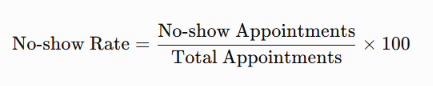

In [ ]:
#2.2 — Calculate clinic-wise no-show rates
query = """
SELECT
    clinic_id,
    COUNT(*) AS total_appointments,
    SUM(no_show) AS total_no_shows,
    ROUND(
        100.0 * SUM(no_show) / COUNT(*),
        2
    ) AS no_show_rate
FROM appointments
GROUP BY clinic_id
ORDER BY no_show_rate DESC;
"""

clinic_analysis = pd.read_sql_query(query, conn)

clinic_analysis

,clinic_id,total_appointments,total_no_shows,no_show_rate
0,C08,90,30,33.33
1,C02,143,39,27.27
2,C04,142,38,26.76
3,C01,160,36,22.50
4,C07,101,21,20.79
5,C06,142,23,16.20
6,C03,82,13,15.85
7,C05,130,18,13.85


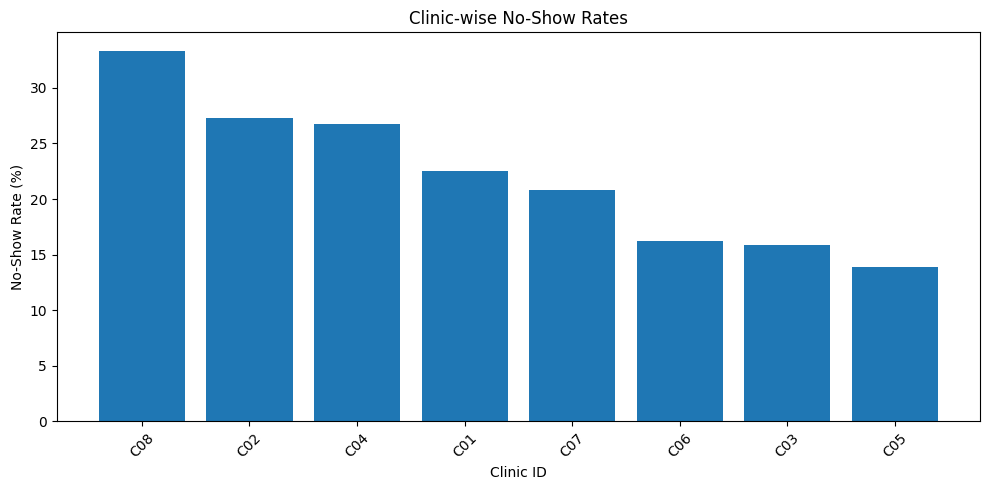

In [ ]:
#2.2.2
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    clinic_analysis["clinic_id"],
    clinic_analysis["no_show_rate"]
)

plt.title("Clinic-wise No-Show Rates")
plt.xlabel("Clinic ID")
plt.ylabel("No-Show Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

 *Clinic C08 has the highest no-show rate at 33.33%, meaning approximately one in every three scheduled appointments is missed. Clinic C05 performs best, with the lowest no-show rate of 13.85%. CareLoop should investigate the reasons behind missed appointments at C08 and consider targeted reminder strategies.*

In [ ]:
#2.3.1 — Lead Days vs No-Show Rate
#lead_days represents the number of days between booking an appointment and the actual appointment date.

query = """
SELECT
    lead_days,
    COUNT(*) AS total_appointments,
    SUM(no_show) AS total_no_shows,
    ROUND(
        100.0 * SUM(no_show) / COUNT(*),
        2
    ) AS no_show_rate
FROM appointments
GROUP BY lead_days
ORDER BY lead_days;
"""

lead_analysis = pd.read_sql_query(query, conn)

lead_analysis

,lead_days,total_appointments,total_no_shows,no_show_rate
0,1,39,4,10.26
1,2,38,4,10.53
2,3,59,10,16.95
3,4,58,9,15.52
4,5,70,14,20.00
5,6,63,8,12.70
6,7,63,14,22.22
7,8,39,4,10.26
8,9,50,12,24.00
9,10,45,9,20.00


### **Impact of Booking Lead Time on No-Show Rates**

The analysis indicates that appointments booked further in advance generally show higher no-show rates. Appointments booked 1–2 days in advance have relatively low no-show rates of approximately 10%, while appointments booked 22–27 days in advance show substantially higher rates, ranging from 28.57% to 53.85%.

Some lead times show 100% no-show rates, but these groups contain very few appointments and should be interpreted cautiously.

**Recommendation:** CareLoop Clinics should consider sending additional reminders to patients who book appointments several weeks in advance. This may help reduce missed appointments.

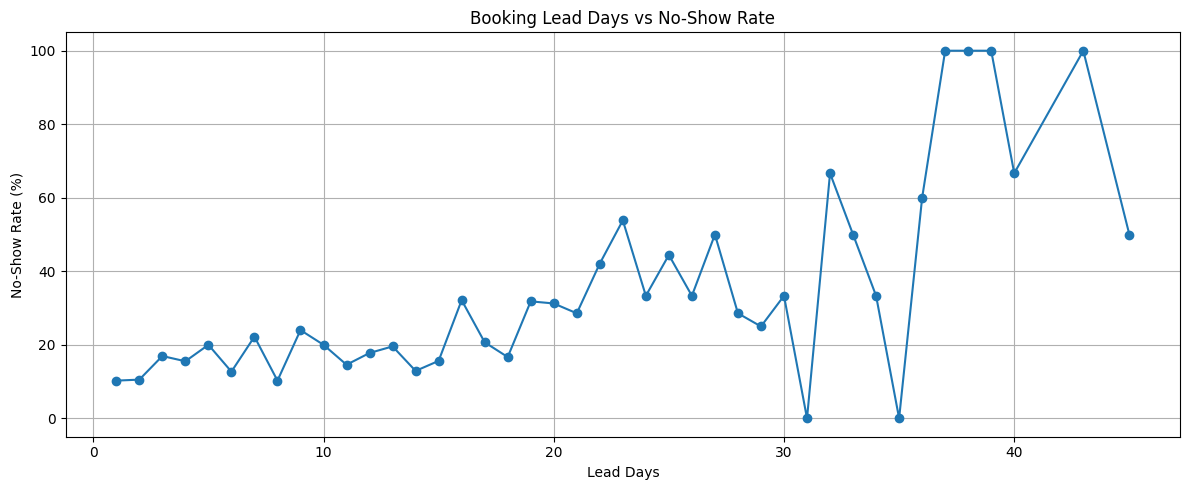

In [ ]:
#2.3.2
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    lead_analysis["lead_days"],
    lead_analysis["no_show_rate"],
    marker="o"
)

plt.title("Booking Lead Days vs No-Show Rate")
plt.xlabel("Lead Days")
plt.ylabel("No-Show Rate (%)")

plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#2.4.1  Reminder effectiveness
query = """
SELECT
    reminder_sent,
    COUNT(*) AS total_appointments,
    SUM(no_show) AS total_no_shows,
    ROUND(
        100.0 * SUM(no_show) / COUNT(*),
        2
    ) AS no_show_rate
FROM appointments
GROUP BY reminder_sent
ORDER BY no_show_rate;
"""

reminder_analysis = pd.read_sql_query(query, conn)

reminder_analysis

,reminder_sent,total_appointments,total_no_shows,no_show_rate
0,Yes,561,86,15.33
1,No,429,132,30.77


### **Effectiveness of Appointment Reminders**

The analysis shows that appointments receiving reminders have a no-show rate of 15.33%, compared with 30.77% for appointments without reminders.

This represents approximately a 50.2% lower observed no-show rate among appointments with reminders.

**Recommendation:** CareLoop Clinics should continue using appointment reminders and consider improving reminder coverage, particularly for patients with longer booking lead times. Further analysis is recommended to account for differences in patient and appointment characteristics before attributing the reduction entirely to reminders.

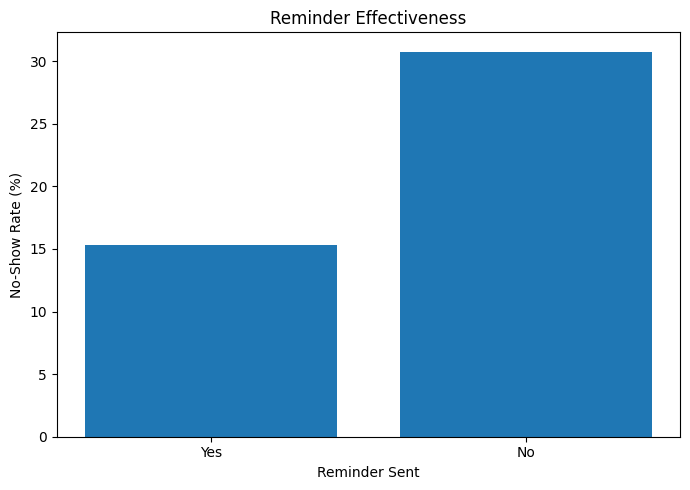

In [ ]:
#2.4.2
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    reminder_analysis["reminder_sent"],
    reminder_analysis["no_show_rate"]
)

plt.title("Reminder Effectiveness")
plt.xlabel("Reminder Sent")
plt.ylabel("No-Show Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
#2.5.1 — Booking Channel Analysis
query = """
SELECT
    booking_channel,
    COUNT(*) AS total_appointments,
    SUM(no_show) AS total_no_shows,
    ROUND(
        100.0 * SUM(no_show) / COUNT(*),
        2
    ) AS no_show_rate
FROM appointments
GROUP BY booking_channel
ORDER BY no_show_rate DESC;
"""

channel_analysis = pd.read_sql_query(query, conn)

channel_analysis

,booking_channel,total_appointments,total_no_shows,no_show_rate
0,Phone,355,99,27.89
1,Walk-In,253,51,20.16
2,App,382,68,17.80


### **Booking Channel and No-Show Analysis**

The analysis indicates that phone bookings have the highest no-show rate at 27.89%, followed by Walk-In bookings at 20.16%. App bookings have the lowest no-show rate at 17.80%.

This suggests that the booking channel is associated with appointment attendance.

**Recommendation:** CareLoop Clinics should investigate why phone bookings experience higher no-show rates. They could improve confirmation procedures, encourage digital reminders, and make it easier for patients to confirm or cancel appointments.

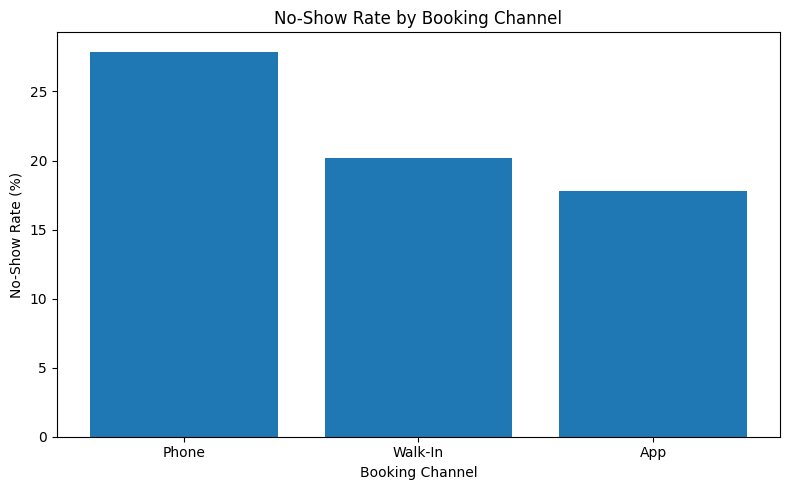

In [ ]:
#2.5.2
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    channel_analysis["booking_channel"],
    channel_analysis["no_show_rate"]
)

plt.title("No-Show Rate by Booking Channel")
plt.xlabel("Booking Channel")
plt.ylabel("No-Show Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
#2.6
query = """
SELECT
    prior_no_shows,
    COUNT(*) AS total_appointments,
    SUM(no_show) AS total_no_shows,
    ROUND(
        100.0 * SUM(no_show) / COUNT(*),
        2
    ) AS no_show_rate
FROM appointments
GROUP BY prior_no_shows
ORDER BY prior_no_shows;
"""

history_analysis = pd.read_sql_query(query, conn)

history_analysis


,prior_no_shows,total_appointments,total_no_shows,no_show_rate
0,0,589,90,15.28
1,1,247,59,23.89
2,2,101,44,43.56
3,3,37,18,48.65
4,4,10,4,40.00
5,5,6,3,50.00


### Impact of Previous No-Shows on Future Attendance

The analysis indicates that patients with a history of missed appointments tend to have higher current no-show rates. Patients with no previous no-shows have a rate of 15.28%, while patients with two and three previous no-shows have rates of 43.56% and 48.65%, respectively.

The results suggest that previous attendance behaviour can be a useful indicator of future appointment risk. However, groups with four or five previous no-shows contain very few appointments and should be interpreted cautiously.

**Recommendation:** CareLoop Clinics should consider identifying patients with repeated previous no-shows and providing them with additional appointment reminders and confirmation calls.

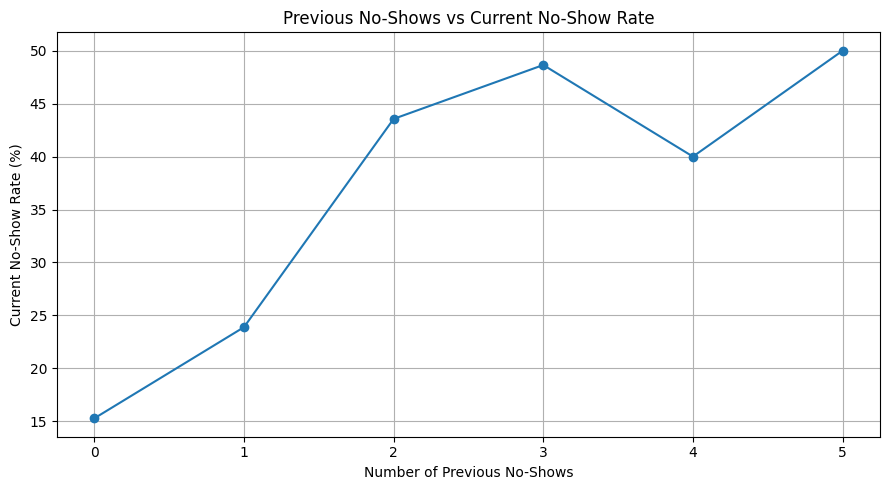

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    history_analysis["prior_no_shows"],
    history_analysis["no_show_rate"],
    marker="o"
)

plt.title("Previous No-Shows vs Current No-Show Rate")
plt.xlabel("Number of Previous No-Shows")
plt.ylabel("Current No-Show Rate (%)")

plt.xticks(history_analysis["prior_no_shows"])
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
#2.7
query = """
SELECT
    visit_type,
    COUNT(*) AS total_appointments,
    SUM(no_show) AS total_no_shows,
    ROUND(
        100.0 * SUM(no_show) / COUNT(*),
        2
    ) AS no_show_rate
FROM appointments
GROUP BY visit_type
ORDER BY no_show_rate DESC;
"""

visit_analysis = pd.read_sql_query(query, conn)
visit_analysis

,visit_type,total_appointments,total_no_shows,no_show_rate
0,Consultation,588,150,25.51
1,Follow-up,402,68,16.92


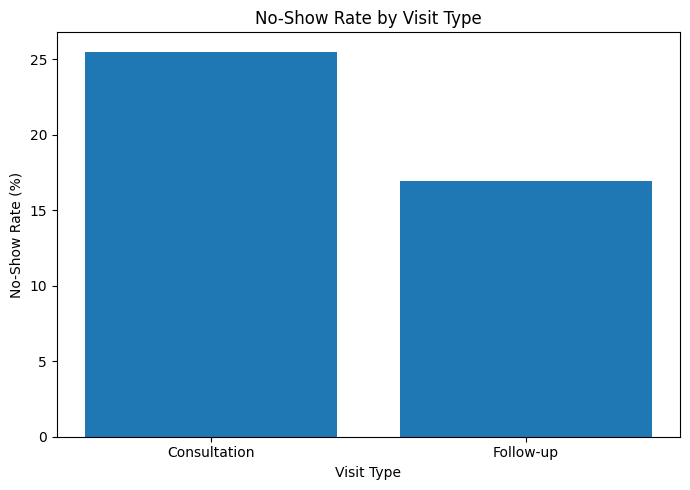

In [ ]:
#2.7 — Visit type analysis
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    visit_analysis["visit_type"],
    visit_analysis["no_show_rate"]
)

plt.title("No-Show Rate by Visit Type")
plt.xlabel("Visit Type")
plt.ylabel("No-Show Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
#2.8 — Age group analysis
query = """
SELECT
    CASE
        WHEN age < 18 THEN 'Under 18'
        WHEN age BETWEEN 18 AND 30 THEN '18-30'
        WHEN age BETWEEN 31 AND 45 THEN '31-45'
        WHEN age BETWEEN 46 AND 60 THEN '46-60'
        ELSE 'Above 60'
    END AS age_group,
    COUNT(*) AS total_appointments,
    SUM(no_show) AS total_no_shows,
    ROUND(
        100.0 * SUM(no_show) / COUNT(*),
        2
    ) AS no_show_rate
FROM appointments
GROUP BY age_group
ORDER BY
    CASE age_group
        WHEN 'Under 18' THEN 1
        WHEN '18-30' THEN 2
        WHEN '31-45' THEN 3
        WHEN '46-60' THEN 4
        ELSE 5
    END;
"""

age_analysis = pd.read_sql_query(query, conn)
age_analysis

,age_group,total_appointments,total_no_shows,no_show_rate
0,18-30,185,60,32.43
1,31-45,270,51,18.89
2,46-60,261,52,19.92
3,Above 60,274,55,20.07


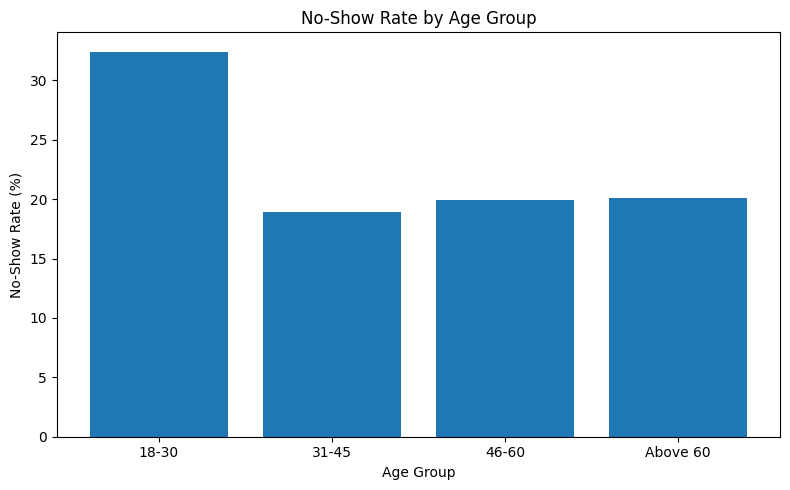

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    age_analysis["age_group"],
    age_analysis["no_show_rate"]
)

plt.title("No-Show Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("No-Show Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
#2.9 — Gender-wise no-show analysis
query = """
SELECT
    gender,
    COUNT(*) AS total_appointments,
    SUM(no_show) AS total_no_shows,
    ROUND(
        100.0 * SUM(no_show) / COUNT(*),
        2
    ) AS no_show_rate
FROM appointments
GROUP BY gender
ORDER BY no_show_rate DESC;
"""

gender_analysis = pd.read_sql_query(query, conn)
gender_analysis

,gender,total_appointments,total_no_shows,no_show_rate
0,M,435,105,24.14
1,F,555,113,20.36


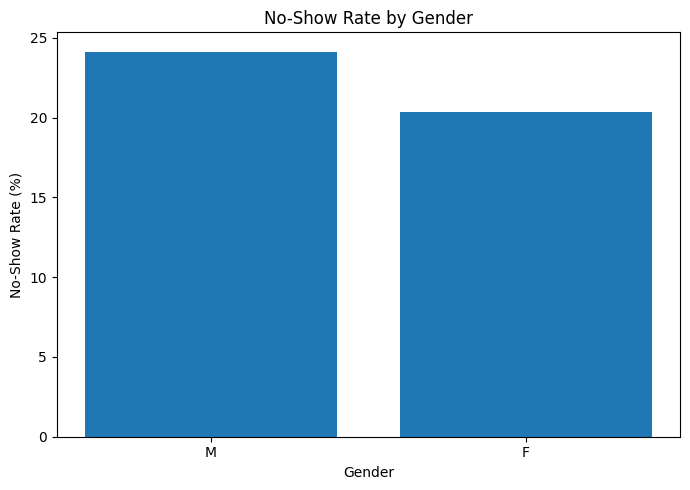

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    gender_analysis["gender"],
    gender_analysis["no_show_rate"]
)

plt.title("No-Show Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("No-Show Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
#2.10 — Distance vs no-show rate
query = """
SELECT
    CASE
        WHEN distance_km <= 5 THEN '0-5 km'
        WHEN distance_km <= 10 THEN '5-10 km'
        WHEN distance_km <= 20 THEN '10-20 km'
        ELSE 'Above 20 km'
    END AS distance_group,
    COUNT(*) AS total_appointments,
    SUM(no_show) AS total_no_shows,
    ROUND(
        100.0 * SUM(no_show) / COUNT(*),
        2
    ) AS no_show_rate
FROM appointments
GROUP BY distance_group
ORDER BY
    CASE distance_group
        WHEN '0-5 km' THEN 1
        WHEN '5-10 km' THEN 2
        WHEN '10-20 km' THEN 3
        ELSE 4
    END;
"""

distance_analysis = pd.read_sql_query(query, conn)
distance_analysis


,distance_group,total_appointments,total_no_shows,no_show_rate
0,0-5 km,286,53,18.53
1,5-10 km,298,60,20.13
2,10-20 km,336,81,24.11
3,Above 20 km,70,24,34.29


Business insight:
- The no-show rate generally increases as distance from the clinic increases.
- Patients living more than 20 km away have the highest observed rate, 34.29%.
- Clinics could consider travel-related support, flexible rescheduling, or earlier reminders for patients travelling longer distances.
- The above-20-km group has only 70 appointments, so interpret its rate with some caution.

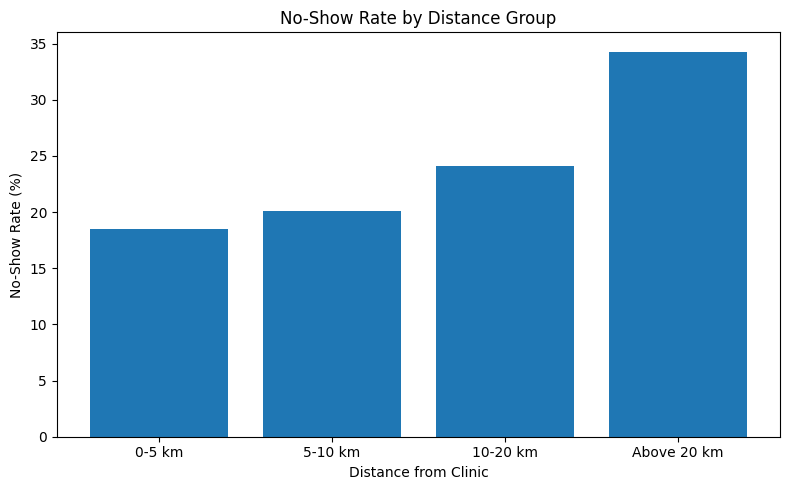

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    distance_analysis["distance_group"],
    distance_analysis["no_show_rate"]
)

plt.title("No-Show Rate by Distance Group")
plt.xlabel("Distance from Clinic")
plt.ylabel("No-Show Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
#2.11 — Appointment status summary
query = """
SELECT
    status,
    COUNT(*) AS total_appointments,
    ROUND(
        100.0 * COUNT(*) / (SELECT COUNT(*) FROM appointments),
        2
    ) AS percentage
FROM appointments
GROUP BY status
ORDER BY total_appointments DESC;
"""

status_analysis = pd.read_sql_query(query, conn)
status_analysis

,status,total_appointments,percentage
0,Attended,772,77.98
1,No-Show,218,22.02


Business insight:
- Approximately 78% of appointments were attended.
- Approximately 22% were missed.
- That's 218 missed appointments out of 990, showing a meaningful opportunity to improve attendance.

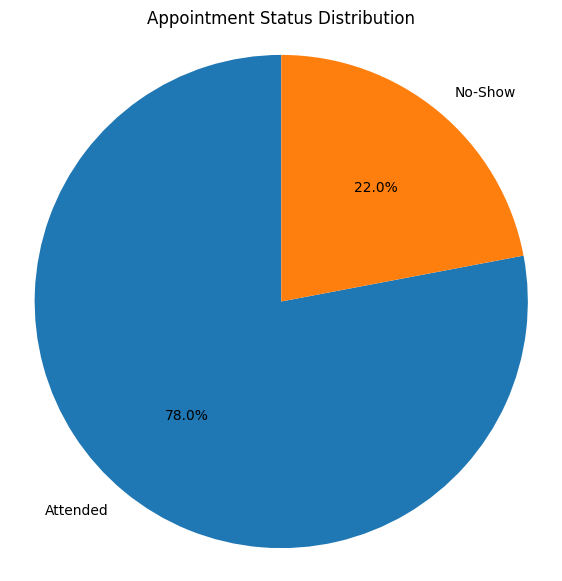

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.pie(
    status_analysis["total_appointments"],
    labels=status_analysis["status"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Appointment Status Distribution")
plt.axis("equal")
plt.show()